In [1]:
!nvidia-smi

Thu Nov 26 04:38:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Cell 1: Install and GPU check

In [2]:
!pip -q install -U transformers datasets accelerate matplotlib

import torch, triton, transformers
print("torch", torch.__version__, "| triton", triton.__version__, "| transformers", transformers.__version__)
print(torch.cuda.get_device_name(0), "| capability", torch.cuda.get_device_capability(0))
assert torch.cuda.is_available()

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
torch 2.14.1+cu130 | triton 3.8.0 | transformers 5.24.1
Tesla T4 | capability (7, 5)


## Cell 2: Config

In [3]:
import os, time, math, json, random
from collections import defaultdict, deque
import numpy as np
import torch
import torch.nn.functional as F

PROCESS_START = time.time()          # for whole-notebook run time

MODEL_NAME   = "Qwen/Qwen2.5-0.5B"   # base model
SEQ_LEN      = 512                   # multiple of FA1_BLOCK
FA1_BLOCK    = 32                    # FA1 tile (Br = Bc); 64 does not fit in the T4's 64 KiB shared memory
TRAIN_TOKENS = 1_000_000
EVAL_TOKENS  = 100_000
MICRO_BS     = 2
GRAD_ACCUM   = 8
LR           = 1e-5
WARMUP_STEPS = 10
LOG_EVERY    = 10
SEED         = 42
OUT_DIR      = "/content/qwen05b_fa1_finetuned"

DEVICE = "cuda"
MiB, GiB = 2**20, 2**30

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## Cell 3: FlashAttention-1 kernels in Triton

In [4]:
import triton
import triton.language as tl

# ---------------- FORWARD (FA1 Algorithm 1) ----------------
@triton.jit
def _fa1_fwd_kernel(Q, K, V, O, M, L, CNT, sm_scale, N,
                    D: tl.constexpr, BR: tl.constexpr, BC: tl.constexpr,
                    CAUSAL: tl.constexpr, COUNT: tl.constexpr):
    bh   = tl.program_id(0)
    base = bh.to(tl.int64) * N * D
    vec  = bh.to(tl.int64) * N
    offs_d = tl.arange(0, D)
    offs_r = tl.arange(0, BR)
    offs_c = tl.arange(0, BC)
    Tc = N // BC
    Tr = N // BR
    for j in range(0, Tc):                                   # outer loop: K/V tiles
        cols = j * BC + offs_c
        kj = tl.load(K + base + cols[:, None] * D + offs_d[None, :])   # HBM -> SRAM
        vj = tl.load(V + base + cols[:, None] * D + offs_d[None, :])   # HBM -> SRAM
        if COUNT:
            tl.atomic_add(CNT + 0, 1)
        if CAUSAL:
            i_lo = (j * BC) // BR
        else:
            i_lo = 0
        for i in range(i_lo, Tr):                            # inner loop: Q/O tiles
            rows = i * BR + offs_r
            qi = tl.load(Q + base + rows[:, None] * D + offs_d[None, :])
            oi = tl.load(O + base + rows[:, None] * D + offs_d[None, :]).to(tl.float32)
            mi = tl.load(M + vec + rows)
            li = tl.load(L + vec + rows)
            if COUNT:
                tl.atomic_add(CNT + 1, 1)
            s = tl.dot(qi, tl.trans(kj)) * sm_scale
            if CAUSAL:
                s = tl.where(rows[:, None] >= cols[None, :], s, float("-inf"))
            m_t = tl.max(s, 1)
            p   = tl.exp(s - m_t[:, None])
            l_t = tl.sum(p, 1)
            m_new = tl.maximum(mi, m_t)
            a = tl.exp(mi - m_new)
            b = tl.exp(m_t - m_new)
            l_new = a * li + b * l_t
            pv = tl.dot(p.to(tl.float16), vj)
            o_new = ((li * a)[:, None] * oi + b[:, None] * pv) / l_new[:, None]
            tl.store(O + base + rows[:, None] * D + offs_d[None, :], o_new.to(tl.float16))
            tl.store(M + vec + rows, m_new)
            tl.store(L + vec + rows, l_new)


# ---------------- BACKWARD (FA1 loop order: K/V outer, Q inner) ----------------
@triton.jit
def _fa1_bwd_kernel(Q, K, V, DO, DQ, DK, DV, M, L, DELTA, CNT, sm_scale, N,
                    D: tl.constexpr, BR: tl.constexpr, BC: tl.constexpr,
                    CAUSAL: tl.constexpr, COUNT: tl.constexpr):
    bh   = tl.program_id(0)
    base = bh.to(tl.int64) * N * D
    vec  = bh.to(tl.int64) * N
    offs_d = tl.arange(0, D)
    offs_r = tl.arange(0, BR)
    offs_c = tl.arange(0, BC)
    Tc = N // BC
    Tr = N // BR
    for j in range(0, Tc):
        cols = j * BC + offs_c
        kj = tl.load(K + base + cols[:, None] * D + offs_d[None, :])   # HBM -> SRAM
        vj = tl.load(V + base + cols[:, None] * D + offs_d[None, :])   # HBM -> SRAM
        if COUNT:
            tl.atomic_add(CNT + 2, 1)
        dk = tl.zeros([BC, D], dtype=tl.float32)
        dv = tl.zeros([BC, D], dtype=tl.float32)
        if CAUSAL:
            i_lo = (j * BC) // BR
        else:
            i_lo = 0
        for i in range(i_lo, Tr):
            rows = i * BR + offs_r
            qi  = tl.load(Q  + base + rows[:, None] * D + offs_d[None, :])
            doi = tl.load(DO + base + rows[:, None] * D + offs_d[None, :])
            mi  = tl.load(M + vec + rows)
            li  = tl.load(L + vec + rows)
            di  = tl.load(DELTA + vec + rows)
            if COUNT:
                tl.atomic_add(CNT + 3, 1)
            s = tl.dot(qi, tl.trans(kj)) * sm_scale
            if CAUSAL:
                s = tl.where(rows[:, None] >= cols[None, :], s, float("-inf"))
            p  = tl.exp(s - mi[:, None]) / li[:, None]
            p16 = p.to(tl.float16)
            dv += tl.dot(tl.trans(p16), doi)
            dp = tl.dot(doi, tl.trans(vj))
            ds = (p * (dp - di[:, None]) * sm_scale).to(tl.float16)
            dk += tl.dot(tl.trans(ds), qi)
            dq_old = tl.load(DQ + base + rows[:, None] * D + offs_d[None, :])
            dq_new = dq_old + tl.dot(ds, kj)
            tl.store(DQ + base + rows[:, None] * D + offs_d[None, :], dq_new)
        tl.store(DK + base + cols[:, None] * D + offs_d[None, :], dk.to(tl.float16))
        tl.store(DV + base + cols[:, None] * D + offs_d[None, :], dv.to(tl.float16))


def fa1_forward(q, k, v, sm_scale, block, cnt=None):
    BH, N, D = q.shape
    o = torch.zeros_like(q)
    m = torch.full((BH, N), float("-inf"), device=q.device, dtype=torch.float32)
    l = torch.zeros((BH, N), device=q.device, dtype=torch.float32)
    dummy = cnt if cnt is not None else torch.zeros(8, dtype=torch.int32, device=q.device)
    _fa1_fwd_kernel[(BH,)](q, k, v, o, m, l, dummy, sm_scale, N,
                           D=D, BR=block, BC=block, CAUSAL=True, COUNT=cnt is not None,
                           num_warps=4, num_stages=1)
    return o, m, l


def fa1_backward(q, k, v, o, m, l, do, sm_scale, block, cnt=None):
    BH, N, D = q.shape
    delta = (do.float() * o.float()).sum(-1).contiguous()
    dq = torch.zeros(q.shape, device=q.device, dtype=torch.float32)
    dk = torch.empty_like(k); dv = torch.empty_like(v)
    dummy = cnt if cnt is not None else torch.zeros(8, dtype=torch.int32, device=q.device)
    _fa1_bwd_kernel[(BH,)](q, k, v, do, dq, dk, dv, m, l, delta, dummy, sm_scale, N,
                           D=D, BR=block, BC=block, CAUSAL=True, COUNT=cnt is not None,
                           num_warps=4, num_stages=1)
    return dq.to(q.dtype), dk, dv


class FA1Func(torch.autograd.Function):
    @staticmethod
    @torch.amp.custom_fwd(device_type="cuda", cast_inputs=torch.float16)
    def forward(ctx, q, k, v, sm_scale, layer_idx):
        B, H, N, D = q.shape
        assert N % FA1_BLOCK == 0, "SEQ_LEN must be a multiple of FA1_BLOCK"
        qf = q.reshape(B * H, N, D).contiguous()
        kf = k.reshape(B * H, N, D).contiguous()
        vf = v.reshape(B * H, N, D).contiguous()
        o, m, l = fa1_forward(qf, kf, vf, sm_scale, FA1_BLOCK)
        ctx.save_for_backward(qf, kf, vf, o, m, l)
        ctx.meta = (B, H, N, D, sm_scale, layer_idx)
        TRAFFIC.record("fwd", layer_idx, B * H, N, D)
        return o.view(B, H, N, D)

    @staticmethod
    @torch.amp.custom_bwd(device_type="cuda")
    def backward(ctx, do):
        qf, kf, vf, o, m, l = ctx.saved_tensors
        B, H, N, D, sm_scale, layer_idx = ctx.meta
        do = do.reshape(B * H, N, D).to(torch.float16).contiguous()
        dq, dk, dv = fa1_backward(qf, kf, vf, o, m, l, do, sm_scale, FA1_BLOCK)
        TRAFFIC.record("bwd", layer_idx, B * H, N, D)
        return dq.view(B, H, N, D), dk.view(B, H, N, D), dv.view(B, H, N, D), None, None

## Cell 4: K/V transfer tracker and schedule display

FA1 schedule for ONE (batch, head): N=512, block=32, d=64, tiles=16
outer j=0: HBM->SRAM  K[0] + V[0]  (8 KiB)
    inner i=0: HBM->SRAM Q[0],O[0],m,l -> compute -> SRAM->HBM O[0],m,l
    inner i=1: HBM->SRAM Q[1],O[1],m,l -> compute -> SRAM->HBM O[1],m,l
    inner i=2: HBM->SRAM Q[2],O[2],m,l -> compute -> SRAM->HBM O[2],m,l
    inner i=3: HBM->SRAM Q[3],O[3],m,l -> compute -> SRAM->HBM O[3],m,l
    inner i=4: HBM->SRAM Q[4],O[4],m,l -> compute -> SRAM->HBM O[4],m,l
    inner i=5: HBM->SRAM Q[5],O[5],m,l -> compute -> SRAM->HBM O[5],m,l
    inner i=6: HBM->SRAM Q[6],O[6],m,l -> compute -> SRAM->HBM O[6],m,l
    inner i=7: HBM->SRAM Q[7],O[7],m,l -> compute -> SRAM->HBM O[7],m,l
    inner i=8: HBM->SRAM Q[8],O[8],m,l -> compute -> SRAM->HBM O[8],m,l
    inner i=9: HBM->SRAM Q[9],O[9],m,l -> compute -> SRAM->HBM O[9],m,l
    inner i=10: HBM->SRAM Q[10],O[10],m,l -> compute -> SRAM->HBM O[10],m,l
    inner i=11: HBM->SRAM Q[11],O[11],m,l -> compute -> SRAM->HBM O[11],m,l
    inner i=12: H

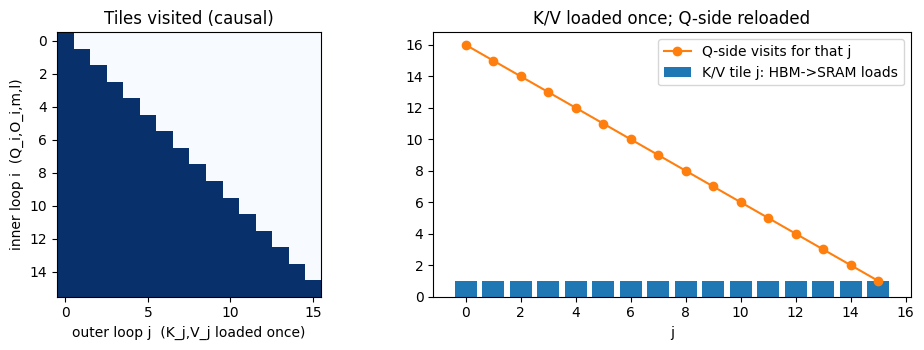

In [5]:
import matplotlib.pyplot as plt

def schedule(N, block, causal=True):
    """Exact tile schedule of the kernels above (per batch*head)."""
    T = N // block
    kv_loads = T
    inner = sum(T - (j if causal else 0) for j in range(T))
    return kv_loads, inner

class Traffic:
    def __init__(self):
        self.enabled = True
        self.total = defaultdict(float)
        self.step = defaultdict(float)
        self.events = deque(maxlen=8)
    def begin_step(self):
        self.step = defaultdict(float)
    def record(self, phase, layer, BH, N, D, block=None, causal=True):
        if not self.enabled:
            return
        block = block or FA1_BLOCK
        kv_loads, inner = schedule(N, block, causal)
        tile  = block * D * 2
        kv_tiles = BH * kv_loads
        kv_bytes = kv_tiles * 2 * tile
        if phase == "fwd":
            q_rd = BH * inner * (2 * tile + 2 * block * 4)
            q_wr = BH * inner * (tile + 2 * block * 4)
        else:
            q_rd = BH * inner * (2 * tile + 3 * block * 4 + block * D * 4)
            q_wr = BH * inner * (block * D * 4) + kv_tiles * 2 * tile
        logical = BH * N * D * 2 * 2
        for d in (self.step, self.total):
            d[f"{phase}_calls"]      += 1
            d[f"{phase}_kv_tiles"]   += kv_tiles
            d[f"{phase}_kv_bytes"]   += kv_bytes
            d[f"{phase}_kv_logical"] += logical
            d[f"{phase}_other_rd"]   += q_rd
            d[f"{phase}_other_wr"]   += q_wr
        self.events.append((phase, layer, BH, kv_tiles, kv_bytes / MiB))

TRAFFIC = Traffic()

def describe_head_schedule(N=SEQ_LEN, block=None, D=64, causal=True, max_events=14):
    block = block or FA1_BLOCK
    T = N // block; tile = block * D * 2
    lines = []
    for j in range(T):
        lines.append(f"outer j={j}: HBM->SRAM  K[{j}] + V[{j}]  ({2*tile/1024:.0f} KiB)")
        for i in range(j if causal else 0, T):
            lines.append(f"    inner i={i}: HBM->SRAM Q[{i}],O[{i}],m,l -> compute -> SRAM->HBM O[{i}],m,l")
    print(f"FA1 schedule for ONE (batch, head): N={N}, block={block}, d={D}, tiles={T}")
    print("\n".join(lines[:max_events]))
    print(f"... {len(lines)} events total | K/V tile loads = {T} (each K/V tile loaded exactly once per pass)")
    vis = np.zeros((T, T))
    for j in range(T):
        for i in range(j if causal else 0, T):
            vis[i, j] = 1
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].imshow(vis, cmap="Blues", origin="upper")
    ax[0].set_xlabel("outer loop j  (K_j,V_j loaded once)")
    ax[0].set_ylabel("inner loop i  (Q_i,O_i,m,l)")
    ax[0].set_title("Tiles visited (causal)")
    ax[1].bar(range(T), [1] * T, label="K/V tile j: HBM->SRAM loads")
    ax[1].plot(range(T), [T - j for j in range(T)], "o-", color="C1", label="Q-side visits for that j")
    ax[1].set_xlabel("j"); ax[1].legend(); ax[1].set_title("K/V loaded once; Q-side reloaded")
    plt.tight_layout(); plt.show()

describe_head_schedule()

## Cell 5: Validate the kernels (with the reason shown if a block size fails)

In [6]:
import re

def tile_kib(block, D=64):
    return block * D * 2 / 1024

def probe_block(block, D=64):
    """Launch forward and backward separately and report which one fails."""
    global FA1_BLOCK
    FA1_BLOCK = block
    N = 2 * block
    q = torch.randn(1, N, D, device=DEVICE, dtype=torch.float16)
    k = torch.randn(1, N, D, device=DEVICE, dtype=torch.float16)
    v = torch.randn(1, N, D, device=DEVICE, dtype=torch.float16)
    sm = D ** -0.5
    failures = {}
    try:
        fa1_forward(q, k, v, sm, block); torch.cuda.synchronize()
    except Exception as e:
        failures["forward"] = e
    try:
        o = torch.zeros_like(q)
        m = torch.zeros(1, N, device=DEVICE, dtype=torch.float32)
        l = torch.ones(1, N, device=DEVICE, dtype=torch.float32)
        fa1_backward(q, k, v, o, m, l, torch.randn_like(q), sm, block); torch.cuda.synchronize()
    except Exception as e:
        failures["backward"] = e
    return failures

def explain_failure(block, failures, D=64):
    props = torch.cuda.get_device_properties(0)
    print(f"[block={block}] FAILED on {props.name}")
    for kernel, e in failures.items():
        print(f"  - {kernel} kernel: {type(e).__name__}")
        print(f"    full message: {e}")
        if type(e).__name__ == "OutOfResources":
            nums = re.findall(r"Required:\s*(\d+).*?limit:\s*(\d+)", str(e))
            if nums:
                need, limit = map(int, nums[0])
                print(f"    needs {need:,} B ({need/1024:.0f} KiB) of shared memory (SRAM) per thread block; "
                      f"this GPU allows {limit:,} B ({limit/1024:.0f} KiB). Over by {(need-limit)/1024:.0f} KiB.")
                print(f"    one {block}x{D} fp16 tile = {tile_kib(block, D):.0f} KiB, so {need/1024/tile_kib(block, D):.1f} tiles' worth "
                      f"must be on-chip at once (K, V, Q, dO, P/dS plus Triton's staging and transposed copies for tl.dot).")
            print(f"    reason: a block of {block} needs more SRAM than the GPU has. "
                  f"Tile memory scales with block x d, so halving the block roughly halves it.")
        else:
            print("    reason: not a shared-memory error. See the full message above.")

def run_validation(block):
    global FA1_BLOCK
    FA1_BLOCK = block
    torch.manual_seed(0)
    B, H, N, D = 2, 3, 256, 64
    q = torch.randn(B, H, N, D, device=DEVICE, dtype=torch.float16, requires_grad=True)
    k = torch.randn(B, H, N, D, device=DEVICE, dtype=torch.float16, requires_grad=True)
    v = torch.randn(B, H, N, D, device=DEVICE, dtype=torch.float16, requires_grad=True)
    sm = D ** -0.5
    qr, kr, vr = [t.detach().float().requires_grad_() for t in (q, k, v)]
    ref = F.scaled_dot_product_attention(qr, kr, vr, is_causal=True)
    g = torch.randn_like(ref)
    ref.backward(g)
    TRAFFIC.enabled = False
    out = FA1Func.apply(q, k, v, sm, 0)
    out.backward(g.half())
    TRAFFIC.enabled = True
    print(f"[block={block}] max err  out={(out.float()-ref).abs().max():.4f}  "
          f"dq={(q.grad.float()-qr.grad).abs().max():.4f}  "
          f"dk={(k.grad.float()-kr.grad).abs().max():.4f}  "
          f"dv={(v.grad.float()-vr.grad).abs().max():.4f}")
    BH = B * H
    qf, kf, vf = [t.detach().reshape(BH, N, D).contiguous() for t in (q, k, v)]
    cnt = torch.zeros(8, dtype=torch.int32, device=DEVICE)
    o, m, l = fa1_forward(qf, kf, vf, sm, block, cnt=cnt)
    fa1_backward(qf, kf, vf, o, m, l, g.half().reshape(BH, N, D).contiguous(), sm, block, cnt=cnt)
    torch.cuda.synchronize()
    kv_loads, inner = schedule(N, block)
    exp = [BH * kv_loads, BH * inner, BH * kv_loads, BH * inner]
    got = cnt[:4].tolist()
    print(f"[block={block}] measured in-kernel [fwd K/V, fwd Q-side, bwd K/V, bwd Q-side] = {got}")
    print(f"[block={block}] analytic schedule                                             = {exp}")
    assert got == exp, "analytic schedule does not match the kernel"
    print(f"OK: block={block} is correct and the K/V tile-load counts match the kernel exactly.")

chosen = None
candidates = (64, 32)
for blk in candidates:
    failures = probe_block(blk)
    if failures:
        explain_failure(blk, failures)
        if blk == candidates[-1]:
            raise RuntimeError("No block size could be launched on this GPU.")
        print(f"  -> falling back to block={candidates[candidates.index(blk) + 1]}\n")
        continue
    print(f"[block={blk}] launches fine (forward and backward).")
    run_validation(blk)
    chosen = blk
    break

FA1_BLOCK = chosen
print("Using FA1_BLOCK =", FA1_BLOCK)

[block=64] FAILED on Tesla T4
  - backward kernel: OutOfResources
    full message: out of resource: shared memory, Required: 81920, Hardware limit: 65536. Reducing block sizes or `num_stages` may help.
    needs 81,920 B (80 KiB) of shared memory (SRAM) per thread block; this GPU allows 65,536 B (64 KiB). Over by 16 KiB.
    one 64x64 fp16 tile = 8 KiB, so 10.0 tiles' worth must be on-chip at once (K, V, Q, dO, P/dS plus Triton's staging and transposed copies for tl.dot).
    reason: a block of 64 needs more SRAM than the GPU has. Tile memory scales with block x d, so halving the block roughly halves it.
  -> falling back to block=32

[block=32] launches fine (forward and backward).
[block=32] max err  out=0.0010  dq=0.0012  dk=0.0013  dv=0.0016
[block=32] measured in-kernel [fwd K/V, fwd Q-side, bwd K/V, bwd Q-side] = [48, 216, 48, 216]
[block=32] analytic schedule                                             = [48, 216, 48, 216]
OK: block=32 is correct and the K/V tile-load counts ma

## Cell 6: FineWeb-Edu data

In [7]:
from datasets import load_dataset
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
ds  = load_dataset("HuggingFaceFW/fineweb-edu", name="sample-10BT", split="train", streaming=True)
it  = iter(ds)

def take_tokens(n_tokens, batch_docs=64):
    ids, total = [], 0
    while total < n_tokens:
        texts = [next(it)["text"] for _ in range(batch_docs)]
        for t in tok(texts, add_special_tokens=False)["input_ids"]:
            t = t + [tok.eos_token_id]
            ids.extend(t); total += len(t)
    return ids[:n_tokens]

def pack(ids):
    n = len(ids) // SEQ_LEN
    return torch.tensor(ids[:n * SEQ_LEN], dtype=torch.long).view(n, SEQ_LEN)

t0 = time.time()
eval_data  = pack(take_tokens(EVAL_TOKENS))
train_data = pack(take_tokens(TRAIN_TOKENS))
print(f"train seqs: {len(train_data)} ({train_data.numel():,} tokens) | eval seqs: {len(eval_data)} | {time.time()-t0:.0f}s")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

train seqs: 1953 (999,936 tokens) | eval seqs: 195 | 6s


## Cell 7: Load Qwen2.5-0.5B (fp32) and plug in the FA1 kernels

In [8]:
from transformers import AutoModelForCausalLM, AttentionInterface
from transformers.models.qwen2.modeling_qwen2 import repeat_kv

def fa1_attention(module, query, key, value, attention_mask, dropout=0.0,
                  scaling=None, sliding_window=None, **kwargs):
    # query: [B, H, N, D]; key/value: [B, H_kv, N, D]. Qwen2.5-0.5B uses GQA, so K/V are expanded to H heads.
    key   = repeat_kv(key,   module.num_key_value_groups)
    value = repeat_kv(value, module.num_key_value_groups)
    scaling = scaling if scaling is not None else module.head_dim ** -0.5
    out = FA1Func.apply(query, key, value, scaling, module.layer_idx)   # causal, no padding (packed data)
    return out.transpose(1, 2).contiguous(), None

AttentionInterface.register("fa1_triton", fa1_attention)
try:
    from transformers.masking_utils import AttentionMaskInterface, sdpa_mask
    AttentionMaskInterface.register("fa1_triton", sdpa_mask)   # mask is ignored by our kernel (always causal)
except Exception as e:
    print("mask registration skipped:", e)

# fp32 master weights: required for AdamW + GradScaler (fp16 only inside autocast)
try:
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32, attn_implementation="fa1_triton")
except TypeError:
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32, attn_implementation="fa1_triton")
model = model.float().to(DEVICE)
model.config.use_cache = False
print("attention impl:", model.config._attn_implementation,
      "| param dtypes:", {str(p.dtype) for p in model.parameters()},
      "| params: %.3fB" % (sum(p.numel() for p in model.parameters()) / 1e9))

# sanity: one forward must hit our kernel once per layer
TRAFFIC.enabled = True; TRAFFIC.begin_step(); TRAFFIC.total.clear()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    model(input_ids=train_data[:1].to(DEVICE))
print("FA1 forward calls in one model forward:", int(TRAFFIC.step["fwd_calls"]),
      "(expected", model.config.num_hidden_layers, ")")
TRAFFIC.total.clear(); TRAFFIC.begin_step()

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

attention impl: fa1_triton | param dtypes: {'torch.float32'} | params: 0.494B
FA1 forward calls in one model forward: 24 (expected 24 )


## Cell 7b: Timed K/V tile kernel (used by the profiler)

In [9]:
import triton, triton.language as tl

@triton.jit
def _clock64(x):
    r = tl.inline_asm_elementwise("mov.u64 $0, %clock64;", "=l,r", [x],
                                  dtype=tl.int64, is_pure=False, pack=1)
    return tl.max(r, 0)

@triton.jit
def _globaltimer(x):
    r = tl.inline_asm_elementwise("mov.u64 $0, %globaltimer;", "=l,r", [x],
                                  dtype=tl.int64, is_pure=False, pack=1)
    return tl.max(r, 0)

@triton.jit
def _fa1_fwd_timed(Q, K, V, O, M, L, LOG, PROG, sm_scale, N, TC,
                   D: tl.constexpr, BR: tl.constexpr, BC: tl.constexpr, CAUSAL: tl.constexpr):
    bh   = tl.program_id(0)
    base = bh.to(tl.int64) * N * D
    vec  = bh.to(tl.int64) * N
    offs_d = tl.arange(0, D)
    offs_r = tl.arange(0, BR)
    offs_c = tl.arange(0, BC)
    Tc = N // BC
    Tr = N // BR
    zero_i = tl.zeros([D], dtype=tl.int32)
    c_start = _clock64(zero_i)
    g_start = _globaltimer(zero_i)
    for j in range(0, Tc):
        t_a = _clock64(zero_i)
        cols = j * BC + offs_c
        kj = tl.load(K + base + cols[:, None] * D + offs_d[None, :])      # HBM -> SRAM
        vj = tl.load(V + base + cols[:, None] * D + offs_d[None, :])
        dep = tl.sum(tl.sum(kj.to(tl.float32), 1), 0) + tl.sum(tl.sum(vj.to(tl.float32), 1), 0)
        t_b = _clock64(zero_i + dep.to(tl.int32))                          # clock read after the tiles arrived
        tl.store(LOG + (bh * TC + j) * 2 + 0, t_b - t_a)                  # K/V tile load cycles
        if CAUSAL:
            i_lo = (j * BC) // BR
        else:
            i_lo = 0
        for i in range(i_lo, Tr):
            rows = i * BR + offs_r
            qi = tl.load(Q + base + rows[:, None] * D + offs_d[None, :])
            oi = tl.load(O + base + rows[:, None] * D + offs_d[None, :]).to(tl.float32)
            mi = tl.load(M + vec + rows)
            li = tl.load(L + vec + rows)
            s = tl.dot(qi, tl.trans(kj)) * sm_scale
            if CAUSAL:
                s = tl.where(rows[:, None] >= cols[None, :], s, float("-inf"))
            m_t = tl.max(s, 1)
            p   = tl.exp(s - m_t[:, None])
            l_t = tl.sum(p, 1)
            m_new = tl.maximum(mi, m_t)
            a = tl.exp(mi - m_new)
            b = tl.exp(m_t - m_new)
            l_new = a * li + b * l_t
            pv = tl.dot(p.to(tl.float16), vj)
            o_new = ((li * a)[:, None] * oi + b[:, None] * pv) / l_new[:, None]
            tl.store(O + base + rows[:, None] * D + offs_d[None, :], o_new.to(tl.float16))
            tl.store(M + vec + rows, m_new)
            tl.store(L + vec + rows, l_new)
        t_c = _clock64(zero_i)
        tl.store(LOG + (bh * TC + j) * 2 + 1, t_c - t_a)                  # whole j-iteration cycles
    c_end = _clock64(zero_i)
    g_end = _globaltimer(zero_i)
    tl.store(PROG + bh * 4 + 0, c_start); tl.store(PROG + bh * 4 + 1, c_end)
    tl.store(PROG + bh * 4 + 2, g_start); tl.store(PROG + bh * 4 + 3, g_end)

def _flush_l2():
    buf = torch.empty(128 * 2**20, dtype=torch.uint8, device=DEVICE)
    buf.zero_(); torch.cuda.synchronize(); del buf

def timed_forward(q, k, v, sm_scale, block):
    BH, N, D = q.shape
    TC = N // block
    def launch():
        o = torch.zeros_like(q)
        m = torch.full((BH, N), float("-inf"), device=DEVICE, dtype=torch.float32)
        l = torch.zeros((BH, N), device=DEVICE, dtype=torch.float32)
        log  = torch.zeros((BH, TC, 2), device=DEVICE, dtype=torch.int64)
        prog = torch.zeros((BH, 4), device=DEVICE, dtype=torch.int64)
        _fa1_fwd_timed[(BH,)](q, k, v, o, m, l, log, prog, sm_scale, N, TC,
                              D=D, BR=block, BC=block, CAUSAL=True, num_warps=4, num_stages=1)
        torch.cuda.synchronize()
        return log, prog
    launch()                 # warm-up: Triton compile
    _flush_l2()              # cold L2, so K/V tiles really come from HBM
    return launch()

print("timed_forward ready:", "timed_forward" in globals())

timed_forward ready: True


## Cell 8: Eval helper and live K/V panel

In [10]:
from IPython.display import clear_output

@torch.no_grad()
def evaluate(model, data, bs=4):
    model.eval(); TRAFFIC.enabled = False
    tot_loss, tot_tok = 0.0, 0
    for i in range(0, len(data), bs):
        x = data[i:i + bs].to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(input_ids=x).logits
        loss = F.cross_entropy(logits[:, :-1].float().reshape(-1, logits.size(-1)),
                               x[:, 1:].reshape(-1), reduction="sum")
        tot_loss += loss.item(); tot_tok += x[:, 1:].numel()
    TRAFFIC.enabled = True; model.train()
    return tot_loss / tot_tok, math.exp(tot_loss / tot_tok)

def kv_panel(history):
    clear_output(wait=True)
    s = TRAFFIC.step
    print("=" * 84)
    print(f"K/V transfers HBM -> SRAM | FlashAttention-1 | Br=Bc={FA1_BLOCK} | N={SEQ_LEN} | d=64")
    print("=" * 84)
    for ph, name in (("fwd", "forward "), ("bwd", "backward")):
        calls = int(s[f"{ph}_calls"])
        if calls:
            print(f"{name}: {calls:4d} kernel calls | K/V tile-pair loads {int(s[f'{ph}_kv_tiles']):>9,} "
                  f"| K/V {s[f'{ph}_kv_bytes']/GiB:7.3f} GiB "
                  f"| loads per K/V element = {s[f'{ph}_kv_bytes']/s[f'{ph}_kv_logical']:.2f}x "
                  f"| Q/O/m/l side {(s[f'{ph}_other_rd']+s[f'{ph}_other_wr'])/GiB:7.3f} GiB")
    print(f"this step total K/V HBM->SRAM : {(s['fwd_kv_bytes']+s['bwd_kv_bytes'])/GiB:.3f} GiB"
          f"   | cumulative: {(TRAFFIC.total['fwd_kv_bytes']+TRAFFIC.total['bwd_kv_bytes'])/GiB:.2f} GiB")
    print("last kernel calls (phase, layer, heads, K/V tile pairs, K/V MiB):")
    for e in list(TRAFFIC.events)[-6:]:
        print(f"   {e[0]} layer {e[1]:>2} heads {e[2]:>3} tiles {e[3]:>5} K/V {e[4]:7.2f} MiB")
    print("-" * 84)
    print(f"{'step':>5} {'loss':>8} {'lr':>9} {'s/step':>7} {'tok/s':>8} {'peakGB':>7} {'K/V GiB/step':>13}")
    for h in history[-10:]:
        print(f"{h['step']:>5} {h['loss']:>8.4f} {h['lr']:>9.2e} {h['sec']:>7.2f} {h['tok_s']:>8.0f} "
              f"{h['peak_gb']:>7.2f} {h['kv_gib']:>13.3f}")

## Cell 9: Baseline eval, training, and K/V timing for every layer and head

K/V transfers HBM -> SRAM | FlashAttention-1 | Br=Bc=32 | N=512 | d=64
forward :  192 kernel calls | K/V tile-pair loads    86,016 | K/V   0.656 GiB | loads per K/V element = 1.00x | Q/O/m/l side   8.716 GiB
backward:  192 kernel calls | K/V tile-pair loads    86,016 | K/V   0.656 GiB | loads per K/V element = 1.00x | Q/O/m/l side  17.652 GiB
this step total K/V HBM->SRAM : 1.312 GiB   | cumulative: 160.12 GiB
last kernel calls (phase, layer, heads, K/V tile pairs, K/V MiB):
   bwd layer  5 heads  28 tiles   448 K/V    3.50 MiB
   bwd layer  4 heads  28 tiles   448 K/V    3.50 MiB
   bwd layer  3 heads  28 tiles   448 K/V    3.50 MiB
   bwd layer  2 heads  28 tiles   448 K/V    3.50 MiB
   bwd layer  1 heads  28 tiles   448 K/V    3.50 MiB
   bwd layer  0 heads  28 tiles   448 K/V    3.50 MiB
------------------------------------------------------------------------------------
 step     loss        lr  s/step    tok/s  peakGB  K/V GiB/step
  113   2.5603  1.18e-06    3.33     2462   11.

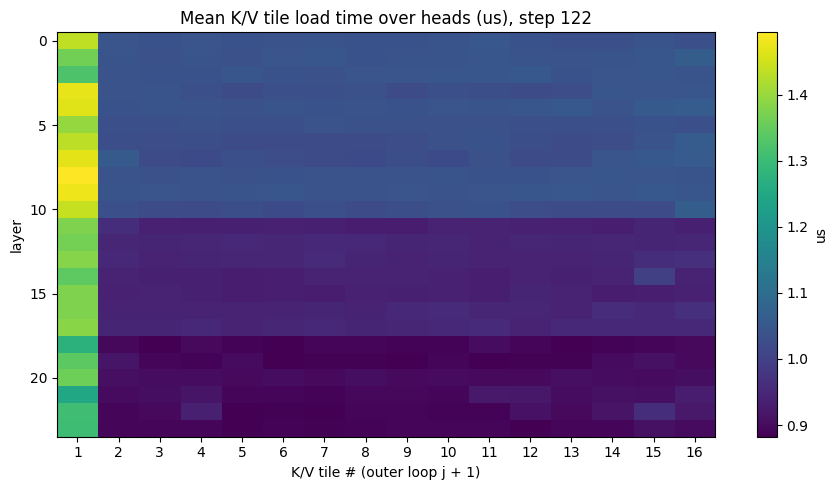

In [11]:
import gc, csv
gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

assert "timed_forward" in globals(), "Run Cell 7b first."
assert {str(p.dtype) for p in model.parameters()} == {"torch.float32"}, "Model must be fp32: re-run Cell 7."

TILE_CSV = "/content/kv_tile_times.csv"
LAYERS   = list(range(model.config.num_hidden_layers))      # all layers
PRINT_EVERY_TILE_LINE = False                               # True: one serial line per (layer, head, tile) = 5,376 lines per logged step

# ---- preflight: same batch through SDPA and through the FA1 kernel ----
def quick_loss(impl, x):
    model.config._attn_implementation = impl
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        return model(input_ids=x, labels=x).loss.item()

model.eval(); TRAFFIC.enabled = False
xb = eval_data[:2].to(DEVICE)
loss_sdpa, loss_fa1 = quick_loss("sdpa", xb), quick_loss("fa1_triton", xb)
model.config._attn_implementation = "fa1_triton"
TRAFFIC.enabled = True; TRAFFIC.total.clear(); TRAFFIC.begin_step(); model.train()
print(f"preflight loss  SDPA: {loss_sdpa:.3f}   FA1 kernel: {loss_fa1:.3f}")
if not (loss_sdpa < 8 and loss_fa1 < 8):
    raise RuntimeError("Loss is far above a sane value (healthy is ~2.5-3.5). "
                       "SDPA broken = weights/fp16 problem; only FA1 broken = kernel problem. Send me both losses.")

# ---- K/V tile profiler: all layers, all heads (separate timed pass, training kernels untouched) ----
def profile_kv_tiles(x_one, layers):
    captured, wanted = {}, set(layers)
    def capturing(module, query, key, value, attention_mask, **kwargs):
        if module.layer_idx in wanted and module.layer_idx not in captured:
            scale = kwargs.get("scaling") or module.head_dim ** -0.5
            captured[module.layer_idx] = (
                query.detach().to(torch.float16).squeeze(0).contiguous(),
                repeat_kv(key,   module.num_key_value_groups).detach().to(torch.float16).squeeze(0).contiguous(),
                repeat_kv(value, module.num_key_value_groups).detach().to(torch.float16).squeeze(0).contiguous(),
                scale)
        return fa1_attention(module, query, key, value, attention_mask, **kwargs)
    prev = TRAFFIC.enabled
    AttentionInterface.register("fa1_triton", capturing)
    TRAFFIC.enabled = False
    try:
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            model(input_ids=x_one)
    finally:
        AttentionInterface.register("fa1_triton", fa1_attention)
        TRAFFIC.enabled = prev
    out = {}
    for layer in layers:
        q, k, v, scale = captured[layer]
        log, prog = timed_forward(q, k, v, scale, FA1_BLOCK)
        out[layer] = (log, prog, q.shape[-1])
    return out

def show_all_heads_timing(layer, log, prog, block, D, every_line=False):
    cycles = (prog[:, 1] - prog[:, 0]).double()
    nanos  = (prog[:, 3] - prog[:, 2]).double()
    ghz    = (cycles.sum() / nanos.sum()).item()
    sec    = (log[:, :, 0].double() / ghz * 1e-9).cpu().numpy()      # [heads, tiles] seconds
    BH, TC = sec.shape
    tile_b = 2 * block * D * 2
    print("=" * (14 + 7 * TC + 16))
    print(f"Layer {layer:02d} | K/V tile HBM->SRAM time per head (us; seconds = us x 1e-6) | "
          f"{tile_b/1024:.0f} KiB per tile pair | clock {ghz:.2f} GHz")
    print(f"head | " + " ".join(f"{t+1:>6}" for t in range(TC)) + " |  total (s)")
    for h in range(BH):
        print(f"H{h:02d}  | " + " ".join(f"{sec[h, t]*1e6:6.2f}" for t in range(TC)) + f" | {sec[h].sum():.9f}")
    print(f"mean | " + " ".join(f"{sec[:, t].mean()*1e6:6.2f}" for t in range(TC)) +
          f" | {sec.sum(1).mean():.9f}")
    if every_line:
        for h in range(BH):
            for t in range(TC):
                print(f"L{layer:02d} H{h:02d} tile {t+1:>2}. K_{t},V_{t}  {tile_b/1024:.0f}Ki  {sec[h, t]:.9f} s")
    return sec

# ---- baseline eval, optimizer, scaler ----
base_loss, base_ppl = evaluate(model, eval_data)
print(f"BEFORE fine-tuning: eval loss {base_loss:.4f} | ppl {base_ppl:.2f}")

model.train()
opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.01, fused=True)
scaler = torch.amp.GradScaler("cuda")
seqs_per_step = MICRO_BS * GRAD_ACCUM
total_steps   = len(train_data) // seqs_per_step
def lr_at(step):
    if step < WARMUP_STEPS: return LR * (step + 1) / WARMUP_STEPS
    p = (step - WARMUP_STEPS) / max(1, total_steps - WARMUP_STEPS)
    return LR * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * p)))

torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
TRAFFIC.total.clear()
perm = torch.randperm(len(train_data))
history, tile_log = [], []
profile_seconds = 0.0
train_start = time.time()

for step in range(total_steps):
    t0 = time.time(); TRAFFIC.begin_step()
    for g in opt.param_groups:
        g["lr"] = lr_at(step)
    step_loss = 0.0
    for micro in range(GRAD_ACCUM):
        a = (step * GRAD_ACCUM + micro) * MICRO_BS
        x = train_data[perm[a:a + MICRO_BS]].to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = model(input_ids=x, labels=x).loss / GRAD_ACCUM
        scaler.scale(loss).backward()
        step_loss += loss.item()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    torch.cuda.synchronize()
    dt = time.time() - t0
    history.append(dict(step=step + 1, loss=step_loss, lr=lr_at(step), sec=dt,
                        tok_s=seqs_per_step * SEQ_LEN / dt,
                        peak_gb=torch.cuda.max_memory_allocated() / GiB,
                        kv_gib=(TRAFFIC.step["fwd_kv_bytes"] + TRAFFIC.step["bwd_kv_bytes"]) / GiB,
                        fwd_kv_gib=TRAFFIC.step["fwd_kv_bytes"] / GiB,
                        bwd_kv_gib=TRAFFIC.step["bwd_kv_bytes"] / GiB))
    if (step + 1) % LOG_EVERY == 0 or step == 0 or step + 1 == total_steps:
        kv_panel(history)
        tp0 = time.time()
        prof = profile_kv_tiles(x[:1], LAYERS)
        print(f"\nStep {step + 1}: serial K/V tile transfer time HBM -> SRAM | forward kernel | "
              f"{len(LAYERS)} layers x all heads | real q/k/v from this step")
        for layer, (log, prog, D) in prof.items():
            sec = show_all_heads_timing(layer, log, prog, FA1_BLOCK, D, every_line=PRINT_EVERY_TILE_LINE)
            tile_log.append(dict(step=step + 1, layer=layer, sec=sec.tolist()))
        profile_seconds += time.time() - tp0

train_seconds = time.time() - train_start - profile_seconds
print(f"\nTraining done: {total_steps} steps in {train_seconds/60:.1f} min "
      f"(+{profile_seconds/60:.1f} min of K/V timing passes) | peak GPU mem {torch.cuda.max_memory_allocated()/GiB:.2f} GiB")

# ---- save every per-tile number and plot a layers x tiles heatmap ----
with open(TILE_CSV, "w", newline="") as f:
    w = csv.writer(f); w.writerow(["step", "layer", "head", "tile", "seconds"])
    for r in tile_log:
        for h, row in enumerate(r["sec"]):
            for t, s in enumerate(row):
                w.writerow([r["step"], r["layer"], h, t, f"{s:.9f}"])
print("saved all per-tile timings to", TILE_CSV)

last_step = tile_log[-1]["step"]
grid = np.array([np.mean(r["sec"], axis=0) * 1e6 for r in tile_log if r["step"] == last_step])
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(grid, aspect="auto", cmap="viridis")
ax.set_xlabel("K/V tile # (outer loop j + 1)"); ax.set_ylabel("layer")
ax.set_xticks(range(grid.shape[1])); ax.set_xticklabels(range(1, grid.shape[1] + 1))
ax.set_title(f"Mean K/V tile load time over heads (us), step {last_step}")
plt.colorbar(im, label="us"); plt.tight_layout(); plt.show()

## Cell 10: Evaluate, save, total training time, auto download

In [12]:
import shutil
from google.colab import files

after_loss, after_ppl = evaluate(model, eval_data)
print(f"AFTER  fine-tuning: eval loss {after_loss:.4f} | ppl {after_ppl:.2f}")
print(f"BEFORE fine-tuning: eval loss {base_loss:.4f} | ppl {base_ppl:.2f}")

model.config._attn_implementation = "sdpa"      # so the saved checkpoint loads without our custom kernel
os.makedirs(OUT_DIR, exist_ok=True)
model.save_pretrained(OUT_DIR); tok.save_pretrained(OUT_DIR)
print("saved to", OUT_DIR)

# total training time
total_s = train_seconds + profile_seconds
print(f"Total training time: {total_s/60:.2f} min ({total_s:.0f} s)  "
      f"[pure training {train_seconds/60:.2f} min + K/V timing passes {profile_seconds/60:.2f} min]")
print(f"Whole notebook run time: {(time.time() - PROCESS_START)/60:.2f} min")

# auto download
zip_path = shutil.make_archive("/content/qwen05b_finetuned", "zip", OUT_DIR)
files.download(zip_path)

AFTER  fine-tuning: eval loss 2.7368 | ppl 15.44
BEFORE fine-tuning: eval loss 2.7499 | ppl 15.64


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved to /content/qwen05b_fa1_finetuned
Total training time: 6.85 min (411 s)  [pure training 6.80 min + K/V timing passes 0.05 min]
Whole notebook run time: 10.53 min


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cell 11: Summary and plots

{
  "steps": 122,
  "train_minutes": 6.797573697566986,
  "kv_profiling_minutes": 0.054622554779052736,
  "tokens_per_sec_avg": 2463.323254711447,
  "peak_gpu_gib": 11.739058494567871,
  "eval_loss_before": 2.749862828470759,
  "eval_loss_after": 2.7368336133312323,
  "ppl_before": 15.640486307610637,
  "ppl_after": 15.438024867605545,
  "fa1_block": 32,
  "seq_len": 512,
  "kv_fwd_gib_total": 80.0625,
  "kv_bwd_gib_total": 80.0625,
  "kv_fwd_tile_pairs_total": 10493952,
  "kv_bwd_tile_pairs_total": 10493952
}


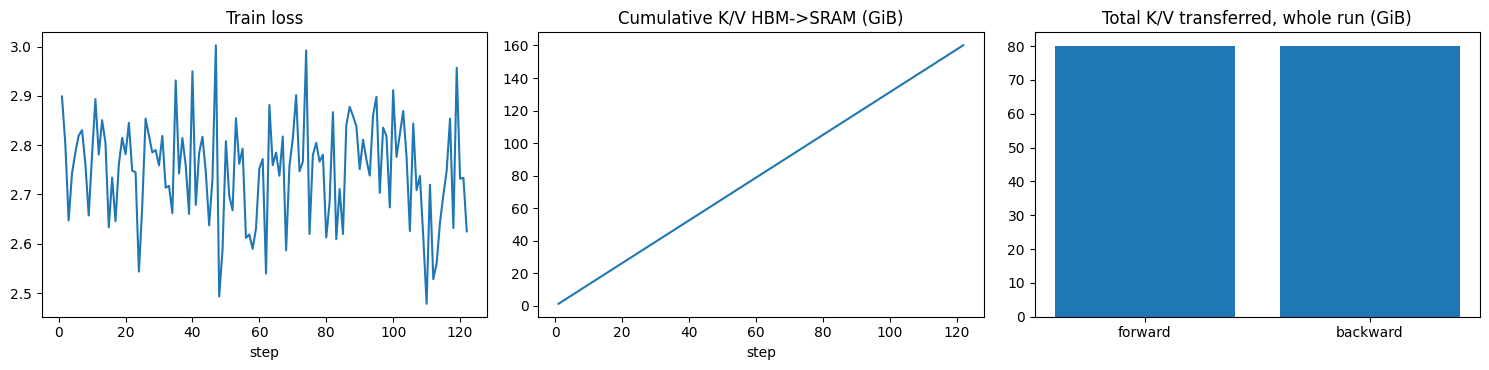

In [13]:
tot = TRAFFIC.total
summary = dict(
    steps=total_steps, train_minutes=train_seconds / 60, kv_profiling_minutes=profile_seconds / 60,
    tokens_per_sec_avg=float(np.mean([h["tok_s"] for h in history])),
    peak_gpu_gib=torch.cuda.max_memory_allocated() / GiB,
    eval_loss_before=base_loss, eval_loss_after=after_loss, ppl_before=base_ppl, ppl_after=after_ppl,
    fa1_block=FA1_BLOCK, seq_len=SEQ_LEN,
    kv_fwd_gib_total=tot["fwd_kv_bytes"] / GiB, kv_bwd_gib_total=tot["bwd_kv_bytes"] / GiB,
    kv_fwd_tile_pairs_total=int(tot["fwd_kv_tiles"]), kv_bwd_tile_pairs_total=int(tot["bwd_kv_tiles"]),
)
print(json.dumps(summary, indent=2))
json.dump(dict(summary=summary, history=history), open(f"{OUT_DIR}/metrics.json", "w"), indent=2)

steps = [h["step"] for h in history]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(steps, [h["loss"] for h in history]); ax[0].set_title("Train loss"); ax[0].set_xlabel("step")
ax[1].plot(steps, np.cumsum([h["kv_gib"] for h in history]))
ax[1].set_title("Cumulative K/V HBM->SRAM (GiB)"); ax[1].set_xlabel("step")
ax[2].bar(["forward", "backward"], [tot["fwd_kv_bytes"] / GiB, tot["bwd_kv_bytes"] / GiB])
ax[2].set_title("Total K/V transferred, whole run (GiB)")
plt.tight_layout(); plt.show()

## Cell 12: Export for your app (.safetensors and .bin)

In [14]:
import shutil
from google.colab import files

EXPORT_DIR = "/content/qwen05b_app_export"
shutil.rmtree(EXPORT_DIR, ignore_errors=True); os.makedirs(EXPORT_DIR)

model.config._attn_implementation = "sdpa"
model.config.use_cache = True
state = {k: v.detach().to("cpu", torch.float16).contiguous() for k, v in model.state_dict().items()}
if model.config.tie_word_embeddings:
    state.pop("lm_head.weight", None)            # tied to the input embeddings; avoids storing it twice

model.save_pretrained(EXPORT_DIR, state_dict=state, safe_serialization=True)   # model.safetensors + config
torch.save(state, f"{EXPORT_DIR}/pytorch_model.bin")                            # .bin
tok.save_pretrained(EXPORT_DIR)

for f in sorted(os.listdir(EXPORT_DIR)):
    print(f"{f:30s} {os.path.getsize(f'{EXPORT_DIR}/{f}')/MiB:8.1f} MiB")

zip_path = shutil.make_archive("/content/qwen05b_app_export", "zip", EXPORT_DIR)
files.download(zip_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

chat_template.jinja                 0.0 MiB
config.json                         0.0 MiB
generation_config.json              0.0 MiB
model.safetensors                 942.3 MiB
pytorch_model.bin                 942.4 MiB
tokenizer.json                     10.9 MiB
tokenizer_config.json               0.0 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>